In [1]:
import pandas as pd
import numpy as np

In [2]:
# Load Dataset

In [3]:
df = pd.read_csv('sales_data_sample.csv', encoding='latin1')
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [4]:
# 3 Preprocess the dataset

In [5]:
x = df[['QUANTITYORDERED', 'SALES']]
x = x.dropna()

In [6]:
# normalization of data

In [7]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

In [8]:
# Find optimal clusters using Elbow Method

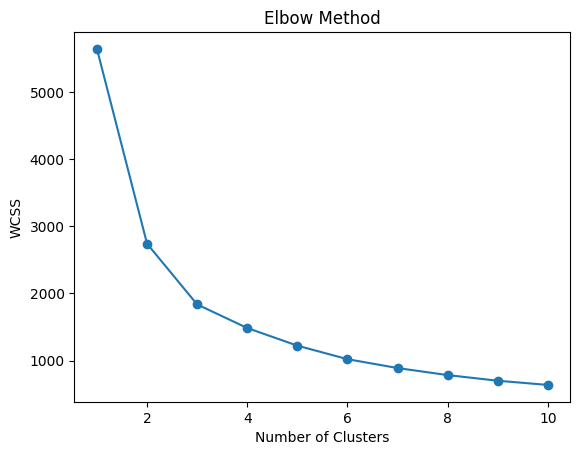

In [9]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering

wcss = []

for i in range(1, 11) :
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1,11), wcss, marker='o')

plt.title('Elbow Method')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.show()

In [10]:
# implement K-Mean clustering

In [11]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

y_kmeans = kmeans.fit_predict(x_scaled)

print("K-Means Cluster Labels:")
print(y_kmeans)

K-Means Cluster Labels:
[1 2 2 ... 0 1 2]


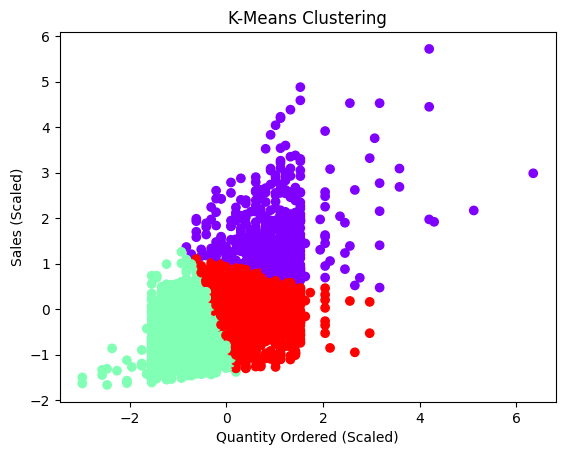

In [12]:
# visualize cluster
plt.scatter(
    x_scaled[:,0], x_scaled[:,1], c = y_kmeans, cmap='rainbow'
)

plt.title('K-Means Clustering')
plt.xlabel('Quantity Ordered (Scaled)')
plt.ylabel('Sales (Scaled)')
plt.show()

In [13]:
# Implement Hierarchical Clustering

In [14]:
hc = AgglomerativeClustering(n_clusters=3, linkage='ward')
y_hc = hc.fit_predict(x_scaled)

print("Hierarchical Clustering:")
print(y_hc)

Hierarchical Clustering:
[0 0 0 ... 1 0 2]


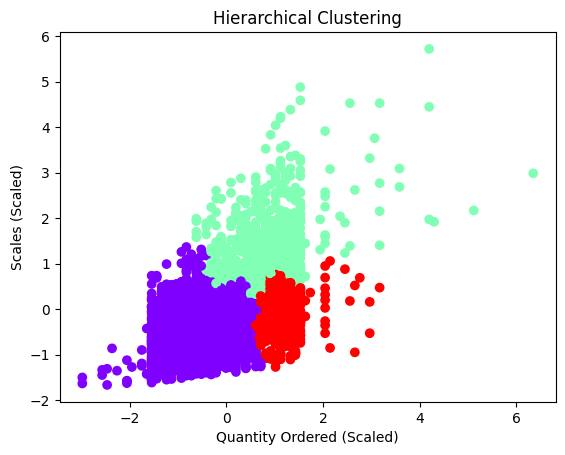

In [15]:
# Display of cluster visualization
plt.scatter(
    x_scaled[:,0],
    x_scaled[:,1],
    c=y_hc,
    cmap='rainbow'
)

plt.title('Hierarchical Clustering')
plt.xlabel('Quantity Ordered (Scaled)')
plt.ylabel('Scales (Scaled)')
plt.show()

In [16]:
print("K-Means Cluster Counts:")
print(pd.Series(y_kmeans).value_counts())

print("Hierarchical Cluster Counts:")
print(pd.Series(y_hc).value_counts())

K-Means Cluster Counts:
1    1259
2    1044
0     520
Name: count, dtype: int64
Hierarchical Cluster Counts:
0    1735
1     624
2     464
Name: count, dtype: int64
